Text(value='puntos_observacion.shp', description='Ruta Eje/Puntos SHP:', layout=Layout(width='80%'))

Dropdown(description='Seleccionar Elemento:', layout=Layout(width='80%'), options=(('Carga el SHP primero', -1…

Text(value='terreno_partidor.tif', description='Ruta Terreno DEM:', layout=Layout(width='80%'))

Text(value='Depth (Max).Terrain.terreno_partidor.tif', description='Ruta Tirante:', layout=Layout(width='80%')…

Text(value='Velocity (Max).Terrain.terreno_partidor.tif', description='Ruta Velocidad:', layout=Layout(width='…

Checkbox(value=False, description='Forzar Escala Terreno 1:1')

Button(button_style='success', description='🚀 CALCULAR ELEMENTO SELECCIONADO', layout=Layout(height='40px', wi…

Output()

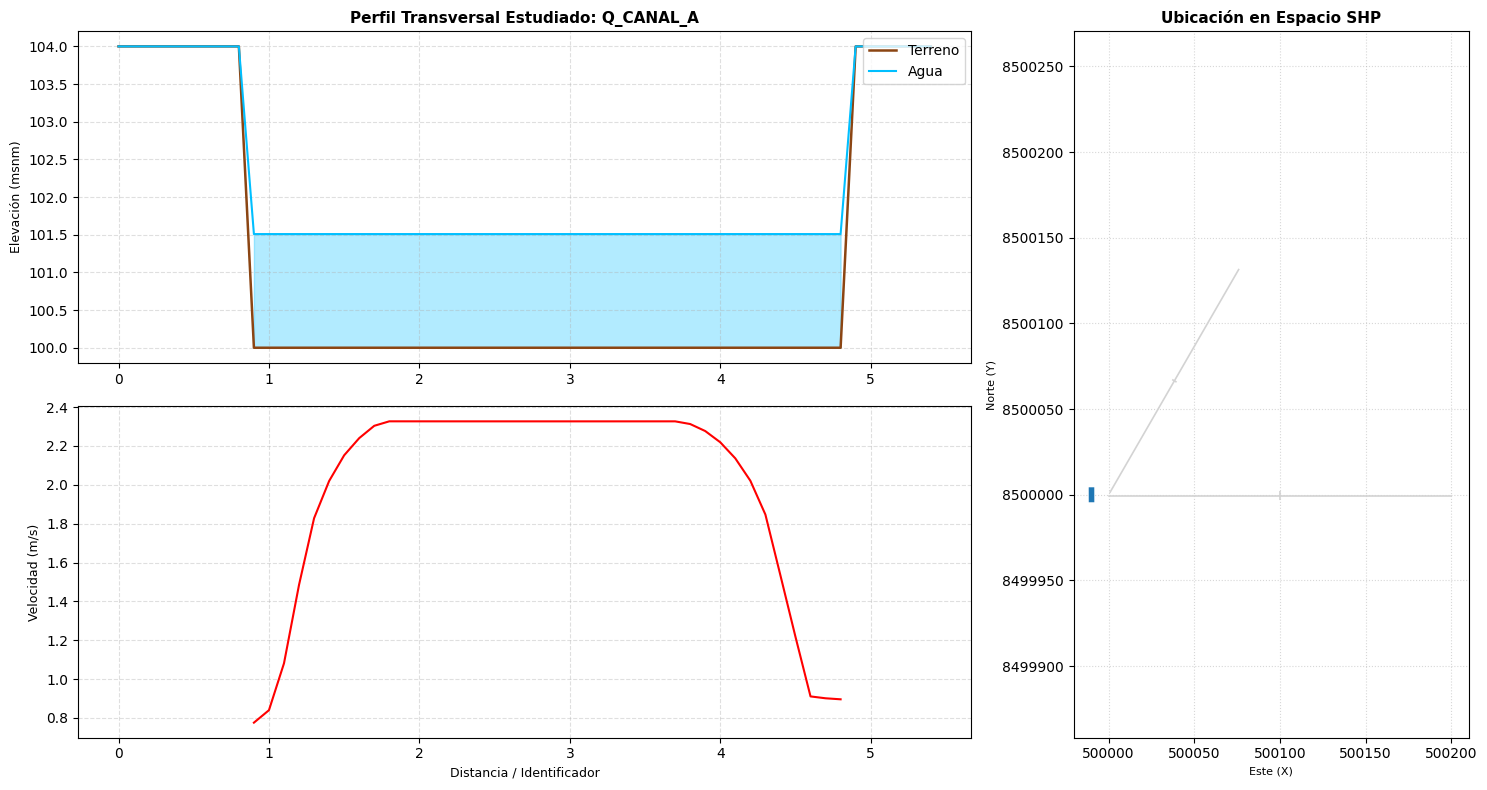


📈 Vista previa de los datos:


,Distancia_m,Este_X,Norte_Y,Terreno_msnm,Tirante_m,NivelAgua_msnm,Velocidad_ms,CaudalLocal_m3s
0,0.0,499990.000000,8.499997e+06,104.0,0.000,104.000,0.00,0.000
1,0.1,499989.999669,8.499997e+06,104.0,0.000,104.000,0.00,0.000
2,0.2,499989.999337,8.499997e+06,104.0,0.000,104.000,0.00,0.000
3,0.3,499989.999006,8.499997e+06,104.0,0.000,104.000,0.00,0.000
4,0.4,499989.998674,8.499998e+06,104.0,0.000,104.000,0.00,0.000
5,0.5,499989.998343,8.499998e+06,104.0,0.000,104.000,0.00,0.000
6,0.6,499989.998011,8.499998e+06,104.0,0.000,104.000,0.00,0.000
7,0.7,499989.997680,8.499998e+06,104.0,0.000,104.000,0.00,0.000
8,0.8,499989.997348,8.499998e+06,104.0,0.000,104.000,0.00,0.000
9,0.9,499989.997017,8.499998e+06,100.0,1.509,101.509,0.78,0.117



📥 Descargando archivo de resultados...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# NOTA:Subir en archivos de colab los siguientes datos: perfiles_y_caudal.shp,el terreno en formato .tiff,
# El depth y la velocidad modelados en formato .TIF

# 1. INSTALACIÓN DE LIBRERÍAS
# Instala las bibliotecas necesarias en Google Colab. Si ya están instaladas,
# pip comprobará sus versiones y no es necesario modificar esta línea.
!pip install rasterio fiona shapely ipywidgets

# 2. IMPORTACIÓN DE BIBLIOTECAS
import os                         # Comprobar si existen archivos y manejar rutas.
import numpy as np                # Operaciones numéricas con arreglos y matrices.
import pandas as pd               # Organizar los resultados en tablas y exportarlos a CSV.
import matplotlib.pyplot as plt   # Crear los gráficos de perfiles y ubicación.
import rasterio                   # Leer los archivos ráster: DEM, tirante y velocidad.
from shapely.geometry import shape # Convertir geometrías del SHP a objetos geométricos.
import fiona                      # Leer entidades, atributos y geometrías de archivos SHP.
import ipywidgets as widgets      # Crear controles interactivos en Google Colab.
from IPython.display import display, HTML, clear_output # Mostrar tablas, mensajes y limpiar salidas.
from google.colab import files    # Descargar el archivo CSV generado al equipo del usuario.

# ==========================================================
# 3. FUNCIONES HIDRÁULICAS
# Cada función recibe los valores muestreados a lo largo del perfil
# y calcula un parámetro hidráulico. dx representa el tamaño de celda
# o espaciamiento entre muestras, expresado en metros.
# ==========================================================

# Calcula el área hidráulica aproximada integrando el tirante a lo largo
# del perfil mediante la regla del trapecio. Las celdas sin dato se toman como 0.
def Area_Hidraulica(depth, dx):
    depth = np.nan_to_num(depth, nan=0.0)
    try:
        return np.trapezoid(depth, dx=dx)
    except AttributeError:
        return np.trapz(depth, dx=dx)

# Estima el ancho mojado sumando el ancho de las celdas cuyo tirante es positivo.
def Ancho_Mojado(depth, dx):
    return np.sum(depth > 0) * dx

# Estima la longitud del perímetro mojado a partir de los segmentos del perfil
# que tienen agua; combina la distancia horizontal dx y el cambio vertical del tirante.
def Perimetro_Mojado(depth, dx):
    depth = np.nan_to_num(depth, nan=0.0)
    wet = depth > 0
    if np.sum(wet) < 2:
        return 0.0
    y = depth[wet]
    dy = np.diff(y)
    ds = np.sqrt(dx**2 + dy**2)
    return np.sum(ds)

# Calcula una velocidad media ponderada por el tirante: las zonas más profundas
# tienen mayor peso. Solo considera las muestras con tirante positivo.
def Velocidad_Media(depth, velocity):
    depth = np.nan_to_num(depth, nan=0.0)
    velocity = np.nan_to_num(velocity, nan=0.0)
    wet = depth > 0
    if not np.any(wet):
        return 0.0
    return np.sum(velocity[wet] * depth[wet]) / np.sum(depth[wet])

# Calcula el número de Froude usando profundidad hidráulica D_h = A/T.
# Clasifica el régimen: subcrítico (Fr<1), crítico (Fr≈1) o supercrítico (Fr>1).
def Numero_Froude(A, T, V_med):
    g = 9.81
    if A <= 0 or T <= 0 or np.isnan(V_med):
        return 0.0, "Sin flujo"
    D_h = A / T
    Fr = V_med / np.sqrt(g * D_h)
    Fr = float(round(Fr, 2))
    reg = "Subcrítico" if Fr < 1 else ("Crítico" if np.isclose(Fr, 1.0, atol=0.05) else "Supercrítico")
    return Fr, reg

# Extrae del ráster el valor de la celda donde cae cada coordenada (X,Y).
# Se utiliza para obtener elevación, tirante y velocidad en los puntos del perfil.
def muestrear_raster(raster_dataset, points):
    values = []
    for p in points:
        try:
            row, col = raster_dataset.index(p[0], p[1])
            val = raster_dataset.read(1)[row, col]
            if val == raster_dataset.nodata:
                val = np.nan
            values.append(val)
        except IndexError:
            values.append(np.nan)
    return np.array(values, dtype=float)

# Variable global que almacena la tabla de resultados del último elemento procesado.
df_puntos_actual = None

# ==========================================================
# 4. INTERFAZ Y PROCESAMIENTO PRINCIPAL
# Permite seleccionar un SHP (líneas o puntos) y los tres rásteres de entrada.
# ==========================================================

# Área de salida donde se mostrarán mensajes, resultados, gráficos y tablas.
output_area = widgets.Output()

# Actualiza el menú desplegable cuando cambia la ruta del archivo SHP.
# Lee los elementos del archivo y muestra su nombre o identificador.
def actualizar_lista_ejes(change):
    path_line = txt_line.value
    if os.path.exists(path_line):
        try:
            # Abre el SHP, identifica si contiene puntos o líneas y obtiene la entidad elegida.
            with fiona.open(path_line) as src:
                opciones = []
                for i, feat in enumerate(src):
                    name = feat['properties'].get('nombre', feat['properties'].get('id', f"Elemento {i}"))
                    opciones.append((f" {i}: {name}", i))
                drp_eje.options = opciones
        except Exception as e:
            drp_eje.options = [("Error al leer archivo SHP", -1)]

# Función principal que se ejecuta al pulsar el botón de cálculo.
# Lee los archivos, muestrea los rásteres, calcula parámetros hidráulicos,
# crea la tabla CSV y presenta los resultados gráficos y numéricos.
def procesar_perfil(b):
    global df_puntos_actual
    with output_area:
        clear_output(wait=True)

        # Recupera las rutas introducidas por el usuario y el elemento seleccionado.
        path_line = txt_line.value
        path_dem = txt_dem.value
        path_depth = txt_depth.value
        path_vel = txt_vel.value
        index_eje = drp_eje.value
        escala_1_1 = chk_scale.value

        # Verifica que se haya seleccionado una entidad y que existan los cuatro archivos.
        if index_eje == -1 or not all([os.path.exists(p) for p in [path_line, path_dem, path_depth, path_vel]]):
            print("❌ Error: Verifica que todos los archivos existan y las rutas sean correctas en tu panel izquierdo.")
            return

        try:
            # Guarda todas las geometrías para dibujarlas luego en el mapa de ubicación.
            todas_las_geometrias = []
            es_punto = False

            with fiona.open(path_line) as src:
                tipo_geom = src.schema['geometry']
                if 'Point' in tipo_geom:
                    es_punto = True

                features = list(src)
                selected_feat = features[index_eje]
                geom = shape(selected_feat['geometry'])
                nombre_eje = selected_feat['properties'].get('nombre', selected_feat['properties'].get('id', f"Punto_{index_eje}"))

                for feat in features:
                    todas_las_geometrias.append(shape(feat['geometry']))

            # Abre simultáneamente los rásteres: elevación del terreno, tirante y velocidad.
            with rasterio.open(path_dem) as dem_src, \
                 rasterio.open(path_depth) as depth_src, \
                 rasterio.open(path_vel) as vel_src:

                # Resolución horizontal del DEM, utilizada como separación entre muestras.
                dx = abs(dem_src.res[0])

                # Si el SHP contiene puntos, se analiza una sola ubicación.
                # Si contiene líneas, se generan puntos de muestreo a intervalos dx.
                if es_punto:
                    dist = np.array([0.0])
                    pts = [(geom.x, geom.y)]
                else:
                    dist = np.arange(0, geom.length, dx)
                    if len(dist) == 0:
                        dist = np.array([0.0])
                    pts = [(geom.interpolate(d).x, geom.interpolate(d).y) for d in dist]

                z = muestrear_raster(dem_src, pts)
                depth_vals = muestrear_raster(depth_src, pts)
                v_vals = muestrear_raster(vel_src, pts)

            # Sustituye tirantes y velocidades negativos o sin dato (NaN) por cero,
            # evitando que esos valores distorsionen los cálculos hidráulicos.
            depth_vals = np.where((depth_vals < 0) | np.isnan(depth_vals), 0.0, depth_vals)
            v_vals = np.where((v_vals < 0) | np.isnan(v_vals), 0.0, v_vals)

            # Para un punto se calculan los parámetros con una sección equivalente
            # de ancho dx. Para una línea se integran los valores de todas las muestras.
            if es_punto:
                val_depth = float(depth_vals[0])
                val_v = float(v_vals[0])
                val_z_scalar = float(z[0])

                A = float(val_depth * dx)
                T = float(dx if val_depth > 0 else 0.0)
                P = float(dx + 2 * val_depth if val_depth > 0 else 0.0)
                Rh = A / P if P > 0 else 0.0
                Vmed = val_v
                Fr, Reg = Numero_Froude(A, T, Vmed)
                caudal_por_punto = val_v * val_depth * dx
                nivel_agua = val_z_scalar + val_depth
            else:
                A = Area_Hidraulica(depth_vals, dx)
                T = Ancho_Mojado(depth_vals, dx)
                P = Perimetro_Mojado(depth_vals, dx)
                Rh = A / P if P > 0 else 0.0
                Vmed = Velocidad_Media(depth_vals, v_vals)
                Fr, Reg = Numero_Froude(A, T, Vmed)
                caudal_por_punto = v_vals * depth_vals * dx
                nivel_agua = z + depth_vals

            # Construye la tabla con distancia, coordenadas, cotas, tirante,
            # nivel de agua, velocidad y caudal local en cada muestra.
            df_puntos_actual = pd.DataFrame({
                'Distancia_m': np.round(dist, 2),
                'Este_X': [p[0] for p in pts],
                'Norte_Y': [p[1] for p in pts],
                'Terreno_msnm': np.round(z, 3),
                'Tirante_m': np.round(depth_vals, 3),
                'NivelAgua_msnm': np.round(nivel_agua, 3),
                'Velocidad_ms': np.round(v_vals, 2),
                'CaudalLocal_m3s': np.round(caudal_por_punto, 4)
            })

            # Exporta la tabla a un archivo CSV que puede abrirse con Excel.
            csv_filename = f"resultado_{nombre_eje}.csv"
            df_puntos_actual.to_csv(csv_filename, index=False)

            tipo_titulo = "Punto de Observación" if es_punto else "Resultados Hidráulicos Globales"
            val_z = float(z[0]) if es_punto else float(z.mean())
            val_h = float(depth_vals[0]) if es_punto else float(depth_vals.mean())
            val_w = float(nivel_agua[0]) if es_punto else float(nivel_agua.mean())

            # Presenta un resumen de los principales resultados hidráulicos.
            display(HTML(f"""
            <div style="background-color: #f8f9fa; border: 1px solid #ddd; padding: 12px; margin-bottom: 15px; border-radius: 4px;">
                <h3 style="margin-top: 0; color: #2c3e50;">📊 {tipo_titulo} - {nombre_eje}:</h3>
                <table style="width: 100%; font-size: 14px;">
                    <tr><td><b>Elevación Terreno:</b> {val_z:.3f} msnm</td><td><b>Tirante (h):</b> {val_h:.3f} m</td></tr>
                    <tr><td><b>Velocidad Media:</b> {Vmed:.2f} m/s</td><td><b>Nivel de Agua:</b> {val_w:.3f} msnm</td></tr>
                    <tr><td><b>Área Calculada (A):</b> {A:.2f} m²</td><td><b>Número de Froude:</b> {Fr} (<span style='color: {"red" if Reg=="Supercrítico" else "blue"}; font-weight:bold;'>{Reg}</span>)</td></tr>
                    <tr><td colspan="2" style="padding-top:10px; color:#27ae60;"><b>💾 Archivo generado listo para descargar automáticamente abajo.</b></td></tr>
                </table>
            </div>
            """))

            # Crea una figura con tres paneles: perfil terreno/agua, velocidad y mapa SHP.
            fig = plt.figure(figsize=(15, 8))
            ax_topo = plt.subplot2grid((2, 3), (0, 0), colspan=2)
            ax_vel = plt.subplot2grid((2, 3), (1, 0), colspan=2, sharex=ax_topo)
            ax_mapa = plt.subplot2grid((2, 3), (0, 2), rowspan=2)
            mask = depth_vals > 0

            # Dibuja de forma diferente según se analice un punto aislado o una línea.
            if es_punto:
                ax_topo.scatter(dist, z, color='#8B4513', s=120, label='Terreno', zorder=3)
                ax_topo.scatter(dist, nivel_agua, color='#00BFFF', s=120, label='Nivel del Agua', zorder=4)
                ax_topo.vlines(dist, z, nivel_agua, colors='#00BFFF', lw=8, alpha=0.6, label='Tirante')
                ax_topo.set_title(f"Muestreo en Punto Fijo: {nombre_eje}", fontsize=11, weight='bold')

                ax_vel.bar(dist, v_vals, color='red', width=0.1, label='Velocidad Local')
                ax_vel.set_xticks(dist)
                ax_vel.set_xticklabels([nombre_eje])
            else:
                ax_topo.plot(dist, z, color='#8B4513', lw=1.8, label='Terreno')
                ax_topo.plot(dist, nivel_agua, color='#00BFFF', lw=1.5, label='Agua')
                ax_topo.fill_between(dist, z, nivel_agua, where=mask, color='#00BFFF', alpha=0.3)
                ax_topo.set_title(f"Perfil Transversal Estudiado: {nombre_eje}", fontsize=11, weight='bold')

                ax_vel.plot(dist, np.where(mask, v_vals, np.nan), color='red', lw=1.5, label='Velocidad')

            ax_topo.set_ylabel("Elevación (msnm)", fontsize=9)
            ax_topo.legend(loc='upper right')
            ax_topo.grid(True, ls='--', alpha=0.4)
            if escala_1_1 and not es_punto:
                ax_topo.set_aspect('equal', adjustable='datalim')

            ax_vel.set_ylabel("Velocidad (m/s)", fontsize=9)
            ax_vel.set_xlabel("Distancia / Identificador", fontsize=9)
            ax_vel.grid(True, ls='--', alpha=0.4)

            # Dibuja todas las entidades del SHP; resalta en azul la seleccionada.
            for i, geometria in enumerate(todas_las_geometrias):
                if es_punto:
                    ax_mapa.scatter(geometria.x, geometria.y, color='#1f77b4' if i==index_eje else '#d3d3d3', s=150 if i==index_eje else 50, zorder=4 if i==index_eje else 2)
                else:
                    x_shp, y_shp = geometria.xy
                    ax_mapa.plot(x_shp, y_shp, color='#1f77b4' if i==index_eje else '#d3d3d3', lw=4.0 if i==index_eje else 1.2)

            ax_mapa.set_title("Ubicación en Espacio SHP", fontsize=11, weight='bold')
            ax_mapa.set_xlabel("Este (X)", fontsize=8)
            ax_mapa.set_ylabel("Norte (Y)", fontsize=8)
            ax_mapa.grid(True, ls=':', alpha=0.5)
            ax_mapa.ticklabel_format(useOffset=False, style='plain')
            ax_mapa.set_aspect('equal', adjustable='datalim')

            # Ajusta los espacios entre paneles y muestra la figura.
            plt.tight_layout()
            plt.show()

            # Muestra las primeras diez filas de la tabla y descarga el CSV.
            print("\n📈 Vista previa de los datos:")
            display(df_puntos_actual.head(10))
            print("\n📥 Descargando archivo de resultados...")
            files.download(csv_filename)

        except Exception as e:
            print(f"❌ Error durante el procesamiento: {str(e)}")

# ==========================================================
# 5. COMPONENTES DE LA INTERFAZ
# Estos controles permiten introducir archivos y ejecutar el análisis.
# ==========================================================
# Campo de texto: ruta del archivo vectorial SHP que contiene líneas o puntos.
txt_line = widgets.Text(value='puntos_observacion.shp', description='Ruta Eje/Puntos SHP:', layout=widgets.Layout(width='80%'))
# Menú desplegable: permite elegir qué línea o punto del SHP será analizado.
drp_eje = widgets.Dropdown(description='Seleccionar Elemento:', options=[("Carga el SHP primero", -1)], layout=widgets.Layout(width='80%'))
# Campo de texto: ruta del DEM/MDT con las elevaciones del terreno (metros sobre el nivel del mar).
txt_dem = widgets.Text(value='terreno_partidor.tif', description='Ruta Terreno DEM:', layout=widgets.Layout(width='80%'))
# Campo de texto: ruta del ráster de tirante o profundidad máxima del agua (m).
txt_depth = widgets.Text(value='Depth (Max).Terrain.terreno_partidor.tif', description='Ruta Tirante:', layout=widgets.Layout(width='80%'))
# Campo de texto: ruta del ráster de velocidad máxima del flujo (m/s).
txt_vel = widgets.Text(value='Velocity (Max).Terrain.terreno_partidor.tif', description='Ruta Velocidad:', layout=widgets.Layout(width='80%'))
# Casilla opcional: fuerza una relación de aspecto 1:1 en el perfil de una línea,
# para que las escalas horizontal y vertical se representen iguales.
chk_scale = widgets.Checkbox(value=False, description='Forzar Escala Terreno 1:1')
# Botón que inicia el procesamiento del elemento seleccionado.
btn_run = widgets.Button(description='🚀 CALCULAR ELEMENTO SELECCIONADO', button_style='success', layout=widgets.Layout(width='45%', height='40px'))

# Vincula el cambio de ruta SHP con la actualización automática del menú de entidades.
txt_line.observe(actualizar_lista_ejes, names='value')
# Vincula el botón con la función que realiza todos los cálculos.
btn_run.on_click(procesar_perfil)

# Muestra en pantalla todos los controles y el área donde aparecerán los resultados.
display(txt_line, drp_eje, txt_dem, txt_depth, txt_vel, chk_scale, btn_run, output_area)
# Ejecuta una primera lectura del SHP para cargar el menú al iniciar el cuaderno.
actualizar_lista_ejes(None)